# 01 · Data Exploration (MIT-BIH Arrhythmia Database)
Goal: understand the data structure, visualize beat types, count classes, and define the patient-disjoint split.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/ECG_Arrhythmia_Classification/src')

!pip install -q wfdb
import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from config import *
print("Train records:", len(DS1), "| Test records:", len(DS2))

Mounted at /content/drive
Train records: 22 | Test records: 21


## 1. Inside one recording

In [2]:
rec = wfdb.rdrecord(f'{RAW_DIR}/100')
ann = wfdb.rdann(f'{RAW_DIR}/100', 'atr')

print("Sampling rate:", rec.fs)
print("Leads:", rec.sig_name)
print("Signal shape:", rec.p_signal.shape)
print("First 10 label positions:", ann.sample[:10])
print("First 10 labels:", ann.symbol[:10])
print("Label counts:", Counter(ann.symbol))

Sampling rate: 360
Leads: ['MLII', 'V5']
Signal shape: (650000, 2)
First 10 label positions: [  18   77  370  662  946 1231 1515 1809 2044 2402]
First 10 labels: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']
Label counts: Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})


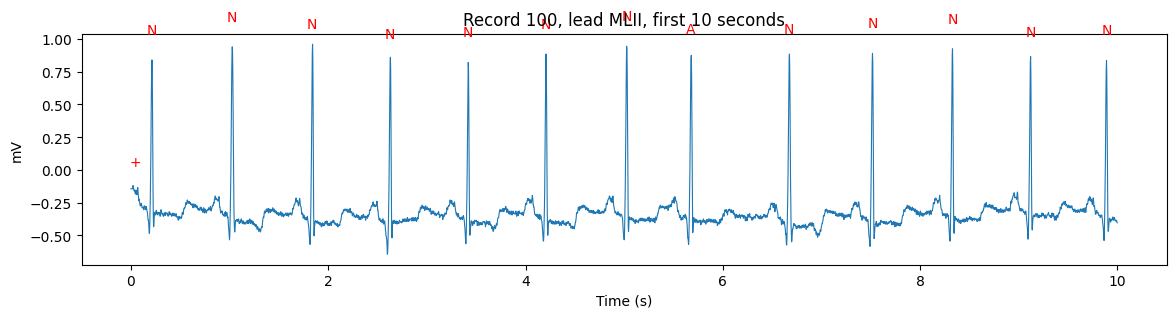

In [3]:
sig = rec.p_signal[:, rec.sig_name.index(LEAD)]
start, end = 0, 10 * FS
t = np.arange(start, end) / FS

plt.figure(figsize=(14, 3))
plt.plot(t, sig[start:end], lw=0.8)
mask = (ann.sample >= start) & (ann.sample < end)
for s, sym in zip(ann.sample[mask], np.array(ann.symbol)[mask]):
    plt.text(s / FS, sig[s] + 0.2, sym, color='red', ha='center')
plt.xlabel('Time (s)'); plt.ylabel('mV')
plt.title('Record 100, lead MLII, first 10 seconds')
plt.savefig(f'{FIG_DIR}/01_record100_10s.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. What do Normal, S and V beats look like?

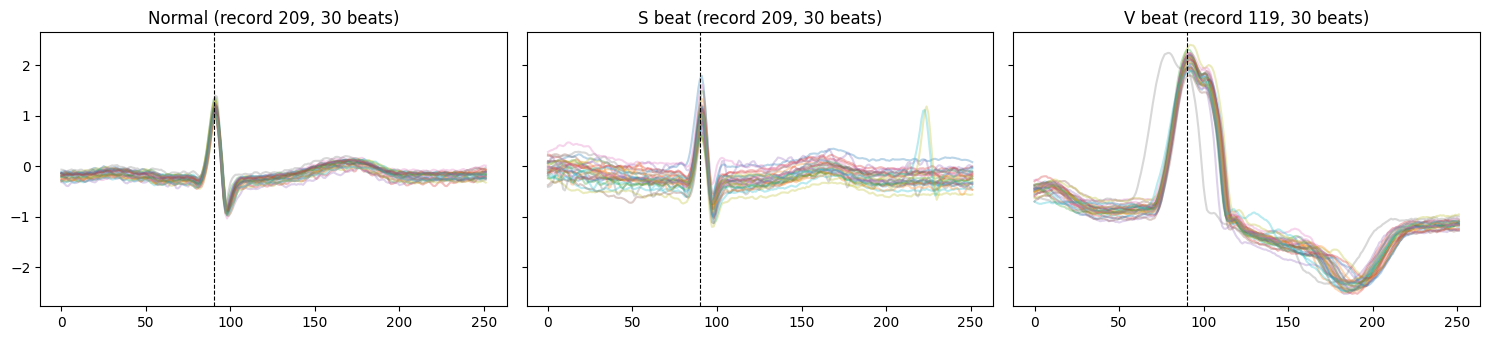

In [4]:
def get_beats(record_id, aami_class, n=30):
    rec = wfdb.rdrecord(f'{RAW_DIR}/{record_id}')
    ann = wfdb.rdann(f'{RAW_DIR}/{record_id}', 'atr')
    sig = rec.p_signal[:, rec.sig_name.index(LEAD)]
    beats = []
    for s, sym in zip(ann.sample, ann.symbol):
        if AAMI.get(sym) == aami_class and s - BEFORE >= 0 and s + AFTER < len(sig):
            beats.append(sig[s - BEFORE : s + AFTER])
        if len(beats) == n:
            break
    return np.array(beats)

examples = [('N', 209, 'Normal'), ('S', 209, 'S beat'), ('V', 119, 'V beat')]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, (cls, rid, title) in zip(axes, examples):
    beats = get_beats(rid, cls)
    for b in beats:
        ax.plot(b, alpha=0.3)
    ax.axvline(BEFORE, color='k', ls='--', lw=0.8)
    ax.set_title(f'{title} (record {rid}, {len(beats)} beats)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/02_beat_shapes_N_S_V.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. S beats are about timing

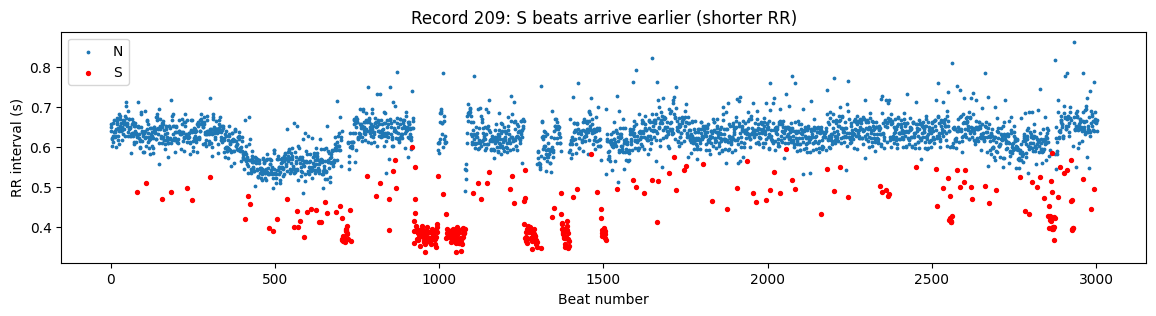

Mean RR, N beats: 0.627 s
Mean RR, S beats: 0.419 s


In [5]:
rec = wfdb.rdrecord(f'{RAW_DIR}/209')
ann = wfdb.rdann(f'{RAW_DIR}/209', 'atr')
beat_idx = [i for i, s in enumerate(ann.symbol) if s in AAMI]
samples = ann.sample[beat_idx]
classes = np.array([AAMI[ann.symbol[i]] for i in beat_idx])

rr = np.diff(samples) / FS          # seconds since previous beat
cls = classes[1:]                   # class of the beat that ended each interval

plt.figure(figsize=(14, 3))
plt.scatter(np.arange(len(rr))[cls == 'N'], rr[cls == 'N'], s=3, label='N')
plt.scatter(np.arange(len(rr))[cls == 'S'], rr[cls == 'S'], s=8, c='red', label='S')
plt.xlabel('Beat number'); plt.ylabel('RR interval (s)')
plt.title('Record 209: S beats arrive earlier (shorter RR)')
plt.legend()
plt.savefig(f'{FIG_DIR}/03_rr_intervals_209.png', dpi=150, bbox_inches='tight')
plt.show()

print("Mean RR, N beats:", rr[cls == 'N'].mean().round(3), "s")
print("Mean RR, S beats:", rr[cls == 'S'].mean().round(3), "s")

## 4. Class distribution per split and per patient

In [6]:
rows = []
for split, recs in [('DS1', DS1), ('DS2', DS2)]:
    for r in recs:
        ann = wfdb.rdann(f'{RAW_DIR}/{r}', 'atr')
        c = Counter(AAMI[s] for s in ann.symbol if s in AAMI)
        rows.append({'split': split, 'record': r, **{k: c.get(k, 0) for k in 'NSVFQ'}})

counts = pd.DataFrame(rows)
counts.to_csv(f'{RES_DIR}/class_counts_per_record.csv', index=False)

print("=== Totals per split ===")
print(counts.groupby('split')[list('NSVFQ')].sum())
print("\n=== DS1 (training pool), per patient ===")
print(counts[counts.split == 'DS1'].to_string(index=False))

=== Totals per split ===
           N     S     V    F  Q
split                           
DS1    45866   944  3788  415  8
DS2    42198  1782  3202  387  7

=== DS1 (training pool), per patient ===
split  record    N   S   V   F  Q
  DS1     101 1860   3   0   0  2
  DS1     106 1507   0 520   0  0
  DS1     108 1740   4  17   2  0
  DS1     109 2492   0  38   2  0
  DS1     112 2537   2   0   0  0
  DS1     114 1820  12  43   4  0
  DS1     115 1953   0   0   0  0
  DS1     116 2302   1 109   0  0
  DS1     118 2166  96  16   0  0
  DS1     119 1543   0 444   0  0
  DS1     122 2476   0   0   0  0
  DS1     124 1536  31  47   5  0
  DS1     201 1635 128 198   2  0
  DS1     203 2529   2 444   1  4
  DS1     205 2571   3  71  11  0
  DS1     207 1543 107 210   0  0
  DS1     208 1586   2 992 373  2
  DS1     209 2621 383   1   0  0
  DS1     215 3195   3 164   1  0
  DS1     220 1954  94   0   0  0
  DS1     223 2045  73 473  14  0
  DS1     230 2255   0   1   0  0


## 5. Final patient-disjoint split

✅ No patient overlap
           N     S     V    F  patients  abnormal_%
set                                                
train  34444   717  3490  398        17        11.8
val    11422   227   298   17         5         4.5
test   42198  1782  3202  387        21        11.3


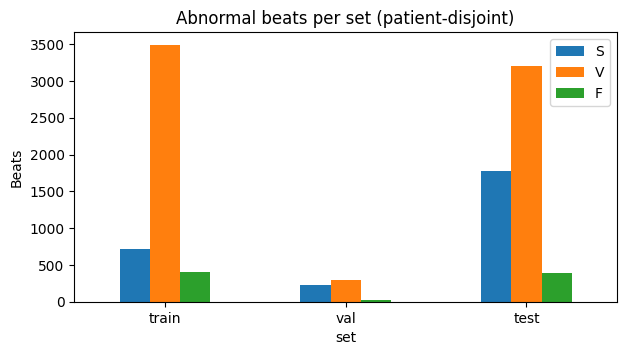

In [7]:
# Safety checks: no patient in two sets
assert set(TRAIN_RECORDS).isdisjoint(VAL_RECORDS)
assert set(TRAIN_RECORDS).isdisjoint(TEST_RECORDS)
assert set(VAL_RECORDS).isdisjoint(TEST_RECORDS)
print("✅ No patient overlap")

def set_name(r):
    return 'train' if r in TRAIN_RECORDS else 'val' if r in VAL_RECORDS else 'test'

counts['set'] = counts['record'].apply(set_name)
summary = counts.groupby('set')[['N', 'S', 'V', 'F']].sum().loc[['train', 'val', 'test']]
summary['patients'] = counts.groupby('set')['record'].count()
summary['abnormal_%'] = (100 * summary[['S', 'V', 'F']].sum(axis=1) /
                         summary[['N', 'S', 'V', 'F']].sum(axis=1)).round(1)
print(summary)
summary.to_csv(f'{RES_DIR}/split_summary.csv')

summary[['S', 'V', 'F']].plot(kind='bar', figsize=(7, 3.5), rot=0)
plt.title('Abnormal beats per set (patient-disjoint)'); plt.ylabel('Beats')
plt.savefig(f'{FIG_DIR}/04_split_abnormal_counts.png', dpi=150, bbox_inches='tight')
plt.show()

## Key findings
- 48 records, 360 Hz, lead MLII used. Beats cut at annotated R-peaks.
- DS1 counts match de Chazal et al. (2004) exactly; DS2 excludes record 202 (same patient as 201).
- Severe imbalance: S beats are only 1.9% of training beats.
- V beats differ in **shape**; S beats look normal but arrive **~33% earlier** (record 209: mean RR 0.42 s vs 0.63 s).
- Abnormal beats are concentrated in few patients; F beats come mostly from one patient (208).
- Validation (118, 124, 205, 215, 220) has only 4.5% abnormal beats → model selection uses macro-F1, not accuracy.
- Test set has 2.5× more S beats than training → S detection will be the hardest part.